### LOF (Local Outlier Factor) is another advanced outlier removal tool

In terms of aggressiveness and behavior, LOF feels like it's between Isolation Forest and Elliptic Envelope. (instructor's personal experience)

In [4]:
# can process the whole dataset
# and compares variables to each other instead
# of focusing on outliers on a single variable

from sklearn.neighbors import LocalOutlierFactor
import pandas as pd

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc.

# basically, this is how aggressive LOF will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers

# note! n_neighbors => LFO is based on the KNN -algorithm
# (K-nearest Neighbors)

lof = LocalOutlierFactor(
    contamination=0.005,
    n_neighbors=20
)

df = pd.read_csv("../houses.csv")

# REMEMBER! LOF is a machine learning algorithm
# => ALL VARIABLES HAVE TO BE NUMERIC AT THIS POINT

# handle these better with your own dataset, here we are simply dropping these
df = df.drop(['id', 'date', 'zipcode', 'lat', 'long'], axis=1)

# fit Local Outlier Factor
y_pred = lof.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred == -1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

# inliers -variables now contain the "cleaned" -version of your data
# etc. => df = inliers.copy()

Inliers: 21504
Outliers: 109


#### It's usually easier to see if we removed enough or too much by visualizing!

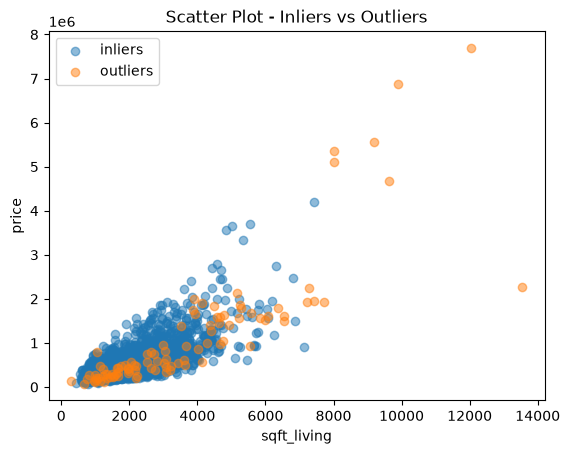

In [5]:
import matplotlib.pyplot as plt

# change the variable if you want to inspect this from other point of views
variable = "sqft_living"
target = "price"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(3000)
outliers_sample = outliers.sample(100)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

In [ ]:
outliers

# LOF selected a variety of different outliers, not as biased 
# as Isolation Forest / Elliptic Envelope, at least with this particular data

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
513,290000.0,4,1.00,1330,8184,1.5,0,0,3,7,1330,0,1949,0,1220,660
722,1578000.0,4,3.25,4670,51836,2.0,0,0,4,12,4670,0,1988,0,4230,41075
918,270000.0,2,1.00,1000,10320,1.0,0,0,3,6,1000,0,1943,0,1100,5160
1144,225500.0,4,2.00,1440,7950,1.0,0,0,5,6,1440,0,1962,0,1530,20037
1149,75000.0,1,0.00,670,43377,1.0,0,0,3,3,670,0,1966,0,1160,42882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21233,469950.0,5,3.00,3223,6371,2.0,0,0,3,9,3223,0,2014,0,1979,19030
21486,1459000.0,4,4.00,4620,130208,2.0,0,0,3,10,4620,0,2014,0,4620,131007
21506,2238890.0,5,6.50,7270,130017,2.0,0,0,3,12,6420,850,2010,0,1800,44890
21520,1408760.0,4,4.00,4920,50621,2.0,0,0,3,10,4280,640,2012,0,4920,74052
